#### Análisis y Procesamiento de Señales

# TS4: Primeras nociones de estimación espectral
#### Juan Martucci

# Análisis y resultados

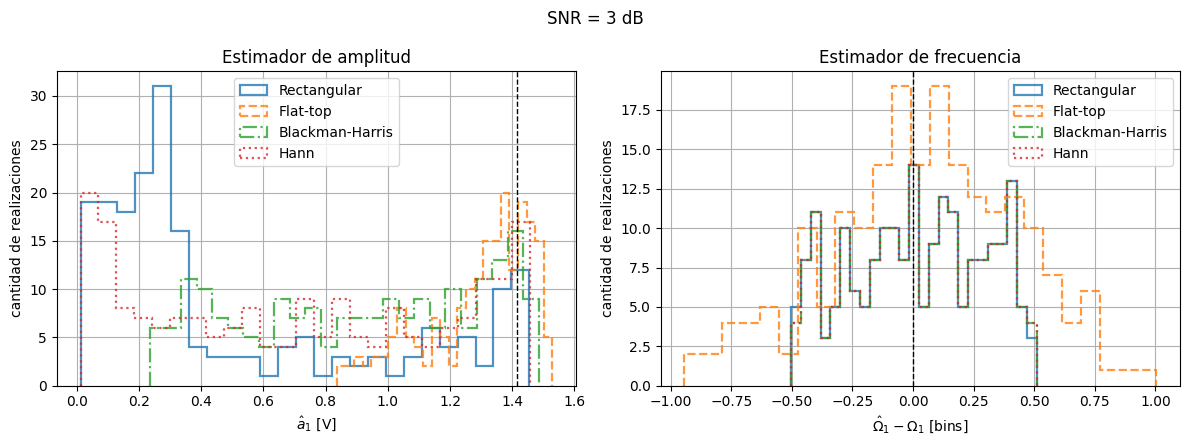

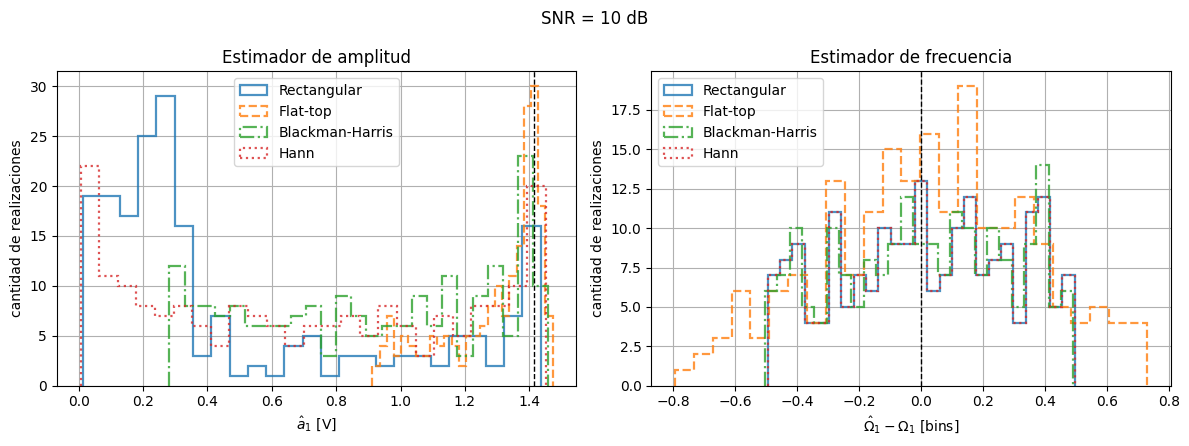


================ SNR = 3 dB ================

Estimación de amplitud [V]
                         sa        va
Rectangular         -0.9118    0.2122
Flat-top            -0.1201    0.0279
Blackman-Harris     -0.4966    0.1434
Hann                -0.7054    0.2359

Estimación de frecuencia [bins]
                         sf        vf
Rectangular          0.0173    0.0762
Flat-top             0.0423    0.1512
Blackman-Harris      0.0223    0.0760
Hann                 0.0223    0.0760

================ SNR = 10 dB ================

Estimación de amplitud [V]
                         sa        va
Rectangular         -0.9172    0.2115
Flat-top            -0.1249    0.0235
Blackman-Harris     -0.5006    0.1390
Hann                -0.7120    0.2356

Estimación de frecuencia [bins]
                         sf        vf
Rectangular          0.0173    0.0760
Flat-top             0.0223    0.1105
Blackman-Harris      0.0123    0.0762
Hann                 0.0173    0.0760

======== zero-padding, f

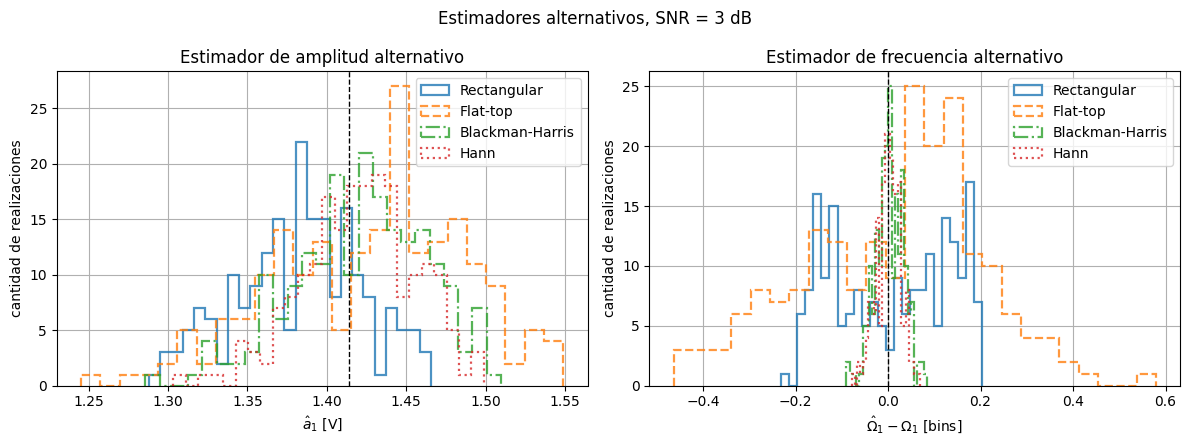

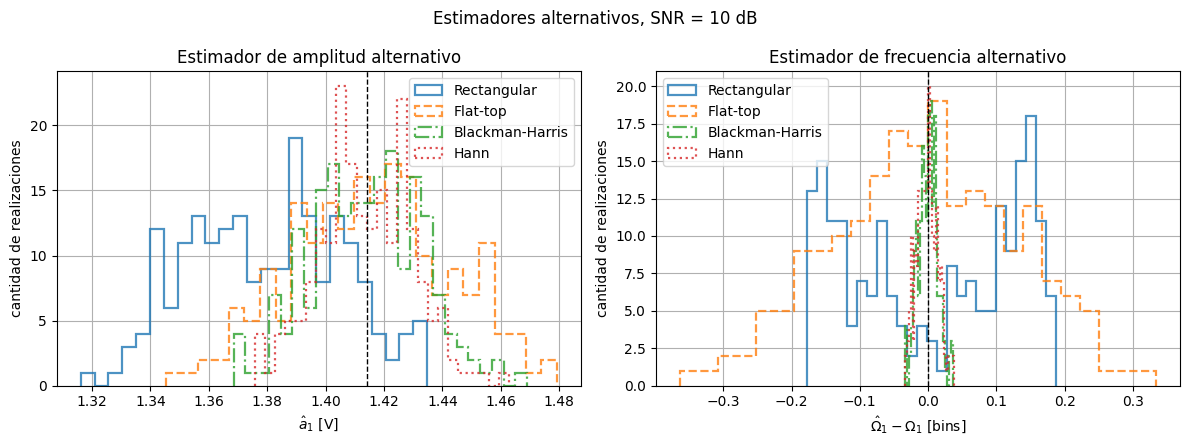


======== Estimadores alternativos, SNR = 3 dB ========

Estimación de amplitud [V]
                         sa        va
Rectangular         -0.0318    0.0015
Flat-top             0.0130    0.0036
Blackman-Harris      0.0070    0.0017
Hann                 0.0058    0.0012

Estimación de frecuencia [bins]
                         sf        vf
Rectangular          0.0102    0.0155
Flat-top             0.0093    0.0381
Blackman-Harris      0.0028    0.0009
Hann                 0.0010    0.0006

======== Estimadores alternativos, SNR = 10 dB ========

Estimación de amplitud [V]
                         sa        va
Rectangular         -0.0345    0.0007
Flat-top             0.0015    0.0007
Blackman-Harris     -0.0001    0.0004
Hann                -0.0004    0.0003

Estimación de frecuencia [bins]
                         sf        vf
Rectangular          0.0078    0.0147
Flat-top            -0.0045    0.0178
Blackman-Harris     -0.0004    0.0002
Hann                -0.0010    0.0002


In [1]:
# -*- coding: utf-8 -*-
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import windows

np.random.seed(12345)


# Parámetros del experimento

N  = 1000                # muestras por realización
M  = 200                 # cantidad de realizaciones
fs = 1000                # Hz
df = fs/N                # resolución espectral -> 1 Hz por bin

a0 = np.sqrt(2)          # así la potencia de la senoidal es a0^2/2 = 1 W
f0 = fs/4                # equivale a Omega0 = pi/2
k0 = int(f0/df)          # bin donde se evalúa el estimador de amplitud

SNRs = [3, 10]           # dB

# las armo periódicas (sym=False) porque es la convención para análisis espectral

ventanas = {'Rectangular'    : np.ones(N),
            'Flat-top'       : windows.flattop(N, sym=False),
            'Blackman-Harris': windows.blackmanharris(N, sym=False),
            'Hann'           : windows.hann(N, sym=False)}

# trazos distintos porque varias ventanas dan histogramas casi iguales y se tapan entre sí

trazos = {'Rectangular': '-', 'Flat-top': '--', 'Blackman-Harris': '-.', 'Hann': ':'}

# uso las mismas desintonías para las dos SNR, así lo único que cambia entre un experimento y el otro es el ruido

fr = np.random.uniform(-2, 2, size=(1, M))
f1 = f0 + fr*df


# Generación de las realizaciones y estimadores

def genera_realizaciones(snr_db):
    # cada columna es una realización, con su propia desintonía
    tt = np.arange(N).reshape(N, 1)/fs
    xx = a0*np.sin(2*np.pi*f1*tt)

    # como la potencia de la senoidal ya vale 1 W, la SNR fija sigma^2
    sigma = np.sqrt(10**(-snr_db/10))
    na = np.random.normal(0, sigma, size=(N, M))

    return xx + na


def estimadores(xx, ww, pad=1):
    # normalizo la ventana por su ganancia coherente para poder comparar amplitudes entre ventanas distintas

    ww = ww/np.mean(ww)
    nfft = pad*N
    XX = np.fft.fft(xx*ww.reshape(-1, 1), n=nfft, axis=0)/N

    # amplitud: módulo del espectro en Omega0 (el x2 es por el espectro de dos lados)
    a_est = 2*np.abs(XX[pad*k0, :])

    # frecuencia: posición del máximo del módulo, buscando en el semiespectro
    kmax = np.argmax(np.abs(XX[:nfft//2, :]), axis=0)
    f_est = kmax*fs/nfft

    # el error de frecuencia lo dejo en bins de la grilla original
    e_est = (f_est - f1.flatten())/df

    return a_est, e_est


# Experimento

tablas = {}
senales = {}

for snr in SNRs:

    xx = genera_realizaciones(snr)
    senales[snr] = xx

    fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))
    fila_a = {}
    fila_f = {}

    for nombre, ww in ventanas.items():

        a_est, e_est = estimadores(xx, ww)

        fila_a[nombre] = [np.mean(a_est) - a0, np.var(a_est)]
        fila_f[nombre] = [np.mean(e_est), np.var(e_est)]

        axs[0].hist(a_est, bins=25, histtype='step', lw=1.6, ls=trazos[nombre], alpha=0.8, label=nombre)
        axs[1].hist(e_est, bins=25, histtype='step', lw=1.6, ls=trazos[nombre], alpha=0.8, label=nombre)

    axs[0].axvline(a0, color='k', ls='--', lw=1)
    axs[0].set_title("Estimador de amplitud")
    axs[0].set_xlabel("$\\hat{a}_1$ [V]")
    axs[0].set_ylabel("cantidad de realizaciones")
    axs[0].legend()
    axs[0].grid(True)

    axs[1].axvline(0, color='k', ls='--', lw=1)
    axs[1].set_title("Estimador de frecuencia")
    axs[1].set_xlabel("$\\hat{\\Omega}_1 - \\Omega_1$ [bins]")
    axs[1].set_ylabel("cantidad de realizaciones")
    axs[1].legend()
    axs[1].grid(True)

    fig.suptitle("SNR = {:d} dB".format(snr))
    plt.tight_layout()
    plt.show()

    tablas[snr] = (fila_a, fila_f)


# Tablas de sesgo y varianza

def imprime_tabla(titulo, filas, etiquetas):
    print("\n" + titulo)
    print("{:<17}{:>10}{:>10}".format("", etiquetas[0], etiquetas[1]))
    for nombre in filas:
        s, v = filas[nombre]
        print("{:<17}{:>10.4f}{:>10.4f}".format(nombre, s, v))


for snr in SNRs:
    tabla_a, tabla_f = tablas[snr]
    print("\n================ SNR = {:d} dB ================".format(snr))
    imprime_tabla("Estimación de amplitud [V]", tabla_a, ["sa", "va"])
    imprime_tabla("Estimación de frecuencia [bins]", tabla_f, ["sf", "vf"])


# Bonus: efecto del zero-padding sobre el estimador de frecuencia

pads = [1, 4, 16]

for snr in SNRs:

    xx = senales[snr]

    print("\n======== zero-padding, frecuencia [bins], SNR = {:d} dB ========".format(snr))
    print("{:<17}".format("") + "".join(["{:>20}".format("x{:d}".format(p)) for p in pads]))
    print("{:<17}".format("") + "".join(["{:>10}{:>10}".format("sf", "vf") for p in pads]))

    for nombre, ww in ventanas.items():
        fila = ""
        for p in pads:
            _, e_est = estimadores(xx, ww, pad=p)
            fila += "{:>10.4f}{:>10.4f}".format(np.mean(e_est), np.var(e_est))
        print("{:<17}".format(nombre) + fila)


# Bonus: estimadores alternativos
# frecuencia: interpolación parabólica del módulo en dB usando el máximo y sus dos vecinos
# amplitud: en vez de mirar siempre Omega0, evalúo la transformada en la frecuencia estimada

def estimadores_alt(xx, ww):
    ww = ww/np.mean(ww)
    xw = xx*ww.reshape(-1, 1)
    XX = np.abs(np.fft.fft(xw, axis=0)/N)[:N//2, :]

    kmax = np.argmax(XX, axis=0)
    cols = np.arange(M)
    Xm = 20*np.log10(XX[kmax-1, cols])
    X0 = 20*np.log10(XX[kmax, cols])
    Xp = 20*np.log10(XX[kmax+1, cols])

    # vértice de la parábola que pasa por los tres puntos, en bins respecto de kmax
    delta = 0.5*(Xm - Xp)/(Xm - 2*X0 + Xp)
    f_est = (kmax + delta)*df
    e_est = (f_est - f1.flatten())/df

    # transformada evaluada en f_est (una frecuencia distinta por realización)
    tt = np.arange(N).reshape(N, 1)/fs
    a_est = 2*np.abs(np.sum(xw*np.exp(-1j*2*np.pi*f_est*tt), axis=0))/N

    return a_est, e_est


tablas_alt = {}

for snr in SNRs:

    xx = senales[snr]

    fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))
    fila_a = {}
    fila_f = {}

    for nombre, ww in ventanas.items():

        a_est, e_est = estimadores_alt(xx, ww)

        fila_a[nombre] = [np.mean(a_est) - a0, np.var(a_est)]
        fila_f[nombre] = [np.mean(e_est), np.var(e_est)]

        axs[0].hist(a_est, bins=25, histtype='step', lw=1.6, ls=trazos[nombre], alpha=0.8, label=nombre)
        axs[1].hist(e_est, bins=25, histtype='step', lw=1.6, ls=trazos[nombre], alpha=0.8, label=nombre)

    axs[0].axvline(a0, color='k', ls='--', lw=1)
    axs[0].set_title("Estimador de amplitud alternativo")
    axs[0].set_xlabel("$\\hat{a}_1$ [V]")
    axs[0].set_ylabel("cantidad de realizaciones")
    axs[0].legend()
    axs[0].grid(True)

    axs[1].axvline(0, color='k', ls='--', lw=1)
    axs[1].set_title("Estimador de frecuencia alternativo")
    axs[1].set_xlabel("$\\hat{\\Omega}_1 - \\Omega_1$ [bins]")
    axs[1].set_ylabel("cantidad de realizaciones")
    axs[1].legend()
    axs[1].grid(True)

    fig.suptitle("Estimadores alternativos, SNR = {:d} dB".format(snr))
    plt.tight_layout()
    plt.show()

    tablas_alt[snr] = (fila_a, fila_f)


for snr in SNRs:
    tabla_a, tabla_f = tablas_alt[snr]
    print("\n======== Estimadores alternativos, SNR = {:d} dB ========".format(snr))
    imprime_tabla("Estimación de amplitud [V]", tabla_a, ["sa", "va"])
    imprime_tabla("Estimación de frecuencia [bins]", tabla_f, ["sf", "vf"])


## Conclusiones

Lo primero que se ve en los histogramas de amplitud es que, salvo la flat-top, ninguna ventana da una campana alrededor de $a_0$. La Hann junta muchas realizaciones pegadas al cero, porque su lóbulo principal se anula en $f_r = \pm 2$ y cerca de ahí el bin $k_0$ casi no lee nada. La rectangular también tiene realizaciones en cero (tiene nulos en $\pm 1$ y $\pm 2$), pero su pico más alto está cerca de 0.3 V: cuando $|f_r|$ está entre 1 y 2 lo que cae en $k_0$ es el primer lóbulo lateral, que está unos 13 dB abajo (0.22 de $a_0$), y como ahí la respuesta cambia poco se amontonan muchos valores parecidos. La Blackman-Harris no llega a anularse en el rango pero cae bastante hacia los bordes, por eso se reparte entre unos 0.25 V y $a_0$. La flat-top es la única concentrada cerca de $a_0$: su lóbulo es tan ancho y chato que aun con 2 bins de desintonía no baja de unos 0.84 V. O sea que estos histogramas muestran básicamente la forma del lóbulo principal de cada ventana evaluada en los $f_r$ que salieron, el ruido casi no se nota.

En el histograma de frecuencia (grafiqué el error $\hat{\Omega}_1 - \Omega_1$ de cada realización, en bins) rectangular, Blackman-Harris y Hann dan curvas casi iguales y se tapan, por eso les puse trazos distintos. Las tres quedan repartidas entre $-0.5$ y $0.5$ bins de forma bastante pareja. La flat-top se abre más y llega a errar hasta 1 bin.

En las tablas, el sesgo de amplitud es negativo para las cuatro ventanas. Es lo esperable, porque el estimador mira siempre $\Omega_0$ y la senoidal está corrida, así que la desintonía solo puede bajar lo que se lee (para poder comparar ventanas escalé el estimador por $2/N$ y normalicé cada ventana por su media, así en sintonía todas leen $a_0$). Va de $-0.91$ V en la rectangular a $-0.12$ V en la flat-top, en el mismo orden que el ancho del lóbulo principal: rectangular, Hann, Blackman-Harris y flat-top.

Con la varianza el orden cambia, y esto no me lo esperaba: la Hann es la peor (0.236), un poco peor que la rectangular (0.212), aunque tiene menos sesgo. La rectangular lee casi siempre valores bajos y eso le achica la dispersión, mientras que la Hann recorre de manera más pareja todo el rango entre 0 y $a_0$, entonces en promedio lee más pero se dispersa más. La flat-top tiene la menor varianza porque casi no cambia con $f_r$.

Entre 3 y 10 dB las tablas de amplitud casi no cambian (la rectangular pasa de $-0.9118$ a $-0.9172$), lo que confirma que acá manda la desintonía: el ruido se reparte en los 1000 bins y en el único bin que se mira aporta poco. Lo poco que cambia va siempre para el mismo lado, con 3 dB el sesgo es un poco menos negativo en las cuatro ventanas. Tiene sentido porque el estimador es un módulo y el ruido le suma algo de energía al bin. De todos modos es chico al lado de la pérdida por desintonía, que es determinística y no se arregla bajando el ruido ni promediando más realizaciones.

En frecuencia, las tres ventanas angostas dan una varianza de 0.076 bins². Como $k_{max}$ termina siendo el bin más cercano a $f_1$, el error es $\mathrm{round}(f_r) - f_r$, y con $f_r \sim U(-2,2)$ eso queda uniforme entre $-0.5$ y $0.5$, cuya varianza es $1/12 = 0.083$. La diferencia con 0.076 es razonable para 200 realizaciones, y que las tres den lo mismo es lógico porque usan las mismas $f_r$. El sesgo que queda (entre 0.012 y 0.022 bins) tampoco es del estimador: el error estándar de la media de esa uniforme con 200 muestras es de unos 0.02 bins, así que está dentro de lo esperable.

La flat-top es la excepción (0.151 a 3 dB). Como su lóbulo es chato, varios bins vecinos tienen módulos parecidos y un poco de ruido alcanza para mover el máximo. Por eso es la única cuya varianza cambia de forma apreciable con la SNR, baja de 0.151 a 0.110 al pasar a 10 dB.

Con zero-padding, en las tres ventanas angostas la varianza baja de 0.076 a unos 0.006 con x4 y a unos 0.0005 con x16. Coincide con el modelo de redondeo sobre una grilla $p$ veces más fina, $1/(12p^2)$, que da 0.0052 y 0.00033, así que en esas ventanas el límite lo ponía la grilla de la DFT. En la flat-top pasa al revés y empeora (de 0.151 a 0.221 con x16 en 3 dB): con la grilla fina el máximo puede caer en cualquier punto de la parte chata del lóbulo y ya no hay redondeo que lo lleve al bin correcto. Para esta ventana el problema es el ancho del lóbulo y agregar ceros no ayuda.

Como estimadores alternativos probé dos cosas. Para frecuencia, ajustar una parábola al módulo en dB con el bin del máximo y sus dos vecinos, y quedarme con el vértice. Para amplitud, en lugar de evaluar siempre en $\Omega_0$, evaluar la transformada en la frecuencia que da la interpolación.

En amplitud la mejora es muy grande. El sesgo queda por debajo de 0.035 V en valor absoluto para todas las ventanas y la varianza baja más de cien veces (la Hann pasa de 0.236 a 0.0012 en 3 dB). Ahora sí pesa el ruido: en flat-top, Blackman-Harris y Hann la varianza baja entre cuatro y cinco veces de 3 a 10 dB. La peor es la rectangular, con $-0.03$ V de sesgo en las dos SNR, porque tiene el lóbulo más angosto y un error chico en la frecuencia ya le baja la lectura.

En frecuencia, con Hann y Blackman-Harris la varianza baja de 0.076 a menos de 0.001 bins² en 3 dB y a 0.0002 en 10 dB, parecido o algo mejor que con zero-padding x16 y sin agrandar la FFT. La rectangular mejora bastante menos (0.015) y su histograma queda con dos grupos cerca de $\pm 0.15$ bins. El lóbulo de la rectangular en dB no se parece a una parábola, entonces la interpolación tiene un error que depende de dónde cayó $f_1$ entre dos bins. La flat-top mejora respecto del estimador original (0.038 contra 0.151 en 3 dB) pero sigue siendo la peor: con un lóbulo tan chato los tres puntos son casi iguales y el ruido mueve mucho el vértice, por eso también mejora a la mitad con 10 dB.

Con los estimadores originales la flat-top era la mejor ventana para amplitud y la peor para frecuencia, y las dos cosas salen de su lóbulo ancho y chato. Con los alternativos la ventaja en amplitud casi desaparece, porque la lectura ya no depende de qué tan plano es el lóbulo alrededor de $\Omega_0$, y Hann y Blackman-Harris quedan como las mejores para los dos parámetros.